# TA-07: Simulasi Sistem Dinamik Akumulasi Polutan PM10 di Udara Jakarta

**Nama/NIM:** WIFA SAPUTRA MAHENDRA - 301240063  
**Mata kuliah:** Pemodelan dan Simulasi  
**Tugas:** TA-07, lanjutan studi kasus TP-07

Notebook ini mensimulasikan konsentrasi PM10 Jakarta sebagai **sistem dinamik orde satu** (stock-flow dengan umpan balik negatif), mengkalibrasi model dengan data ISPU DKI Jakarta, lalu menjalankan eksperimen **What-If** pengurangan emisi.

**Alur notebook:** (1) data, (2) fungsi model, (3) estimasi parameter, (4) simulasi baseline, (5) kalibrasi dan validasi, (6) Euler vs `solve_ivp`, (7) What-If, (8) kesimpulan.

## Penjelasan Model

Konsentrasi PM10 diperlakukan sebagai **stock** *C(t)*. **Inflow** adalah emisi dan gangguan musiman, **outflow** adalah pembersihan alami (angin, hujan, pengendapan) yang sebanding dengan konsentrasi. Karena makin tinggi *C* makin besar pembersihannya, terbentuk **umpan balik negatif** yang menarik sistem ke keadaan setimbang.

$$\frac{dC}{dt} = E_0\,\bigl(1-u(t)\bigr) + d(t) - k\,C$$

$$d(t) = A\,\sin\!\left(\frac{2\pi\,(t-t_0)}{T}\right),\qquad T = 365{,}25\ \text{hari}$$

Metode Euler dengan langkah waktu $\Delta t$:

$$C_{n+1} = C_n + \Delta t\,\bigl[E_0(1-u_n) + d_n - k\,C_n\bigr]$$

Keadaan setimbang (saat $dC/dt=0$ dan $d=0$):

$$C^* = \frac{E_0\,(1-u)}{k}$$

| Simbol | Peran | Keterangan |
|---|---|---|
| $C(t)$ | Stock / output | Indeks ISPU PM10 |
| $k$ | Parameter | Laju pembersihan (1/hari) |
| $E_0$ | Parameter | Emisi dasar (indeks/hari) |
| $d(t)$ | Gangguan | Pengaruh musim hujan/kemarau |
| $u(t)$ | Sinyal kontrol | Fraksi pengurangan emisi (0-1) |
| $C_0$ | Kondisi awal | PM10 pada 1 Januari 2022 |

## 1. Data
Data sekunder ISPU DKI Jakarta (Kaggle: *Air Quality Index in Jakarta*, `ispu_dki_all.csv`). Tahun **2022** dipilih sebagai periode simulasi karena lengkap 365 hari.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from pathlib import Path
from scipy.integrate import solve_ivp
from scipy.optimize import least_squares, curve_fit

plt.rcParams.update({"figure.figsize": (10, 4.5), "axes.grid": True, "grid.alpha": 0.3})

In [2]:
# Cari file data (di repo: data/ispu_dki_all.csv; di Colab: upload ke folder kerja)
for p in ["data/ispu_dki_all.csv", "ispu_dki_all.csv"]:
    if Path(p).exists():
        CSV = p
        break
else:
    raise FileNotFoundError("Upload ispu_dki_all.csv ke folder kerja terlebih dahulu.")

df = pd.read_csv(CSV, parse_dates=["tanggal"]).set_index("tanggal")
pm10 = df["pm10"]
pm10_2022 = pm10.loc["2022"]          # tahun 2022 lengkap 365 hari
y = pm10_2022.values

print("Ukuran data        :", df.shape)
print("Rentang tanggal    :", df.index.min().date(), "sampai", df.index.max().date())
print("PM10 terisi        :", pm10.notna().sum(), "hari")
print("Data 2022          :", len(y), "hari | rata-rata", round(y.mean(), 1), "| sd", round(y.std(ddof=1), 1))

Ukuran data        : (5538, 10)
Rentang tanggal    : 2010-01-01 sampai 2025-02-28
PM10 terisi        : 5223 hari
Data 2022          : 365 hari | rata-rata 59.8 | sd 13.3


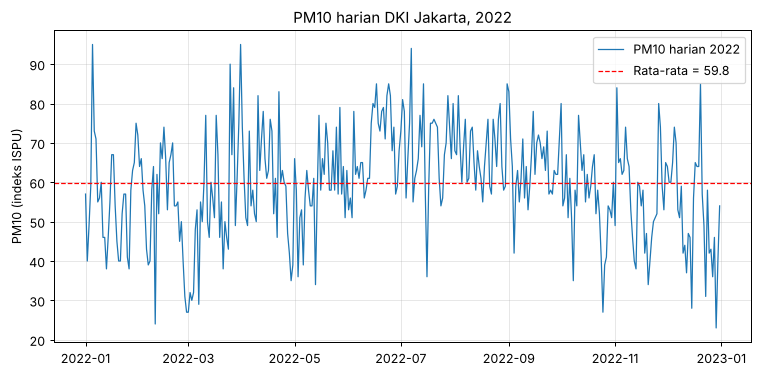

In [3]:
plt.plot(pm10_2022.index, y, lw=1, label="PM10 harian 2022")
plt.axhline(y.mean(), color="red", ls="--", lw=1, label=f"Rata-rata = {y.mean():.1f}")
plt.title("PM10 harian DKI Jakarta, 2022")
plt.ylabel("PM10 (indeks ISPU)")
plt.legend()
plt.show()

## 2. Fungsi Model
Semua fungsi simulasi dikumpulkan di satu cell: estimasi parameter, gangguan musiman, sinyal kontrol, metode Euler, solver SciPy `solve_ivp`, metrik evaluasi, dan kalibrasi.

In [4]:
T_MUSIM = 365.25  # periode gangguan musiman (hari)


def estimasi_k_E0(c):
    """Regresi C(t+1) = a*C(t) + b. Setara Euler dengan dt = 1 hari: k = 1 - a, E0 = b."""
    a, b = np.polyfit(c[:-1], c[1:], 1)
    return 1 - a, b


def gangguan(doy, A, t0):
    """Gangguan musiman d(t) = A * sin(2*pi*(doy - t0) / T)."""
    return A * np.sin(2 * np.pi * (np.asarray(doy, float) - t0) / T_MUSIM)


def kontrol_u(t, jenis="tidak ada", u_maks=0.2, t_mulai=90, t_ramp=90, periode=60):
    """Sinyal kontrol u(t) = fraksi pengurangan emisi (0-1)."""
    t = np.asarray(t, float)
    if jenis == "step":
        return np.where(t >= t_mulai, u_maks, 0.0)
    if jenis == "ramp":
        return u_maks * np.clip((t - t_mulai) / t_ramp, 0.0, 1.0)
    if jenis == "sinusoida":
        return np.where(t >= t_mulai,
                        u_maks / 2 * (1 - np.cos(2 * np.pi * (t - t_mulai) / periode)), 0.0)
    return np.zeros_like(t)


def euler(k, E0, A, t0, C0, u_fn=None, dt=1.0, t_akhir=364, doy_awal=1):
    """Metode Euler: C[n+1] = C[n] + dt * (E0*(1-u) + d - k*C[n])."""
    t = np.arange(0, t_akhir + dt / 2, dt)
    u = np.zeros_like(t) if u_fn is None else u_fn(t)
    d = gangguan(doy_awal + t, A, t0)
    C = np.empty_like(t)
    C[0] = C0
    for n in range(len(t) - 1):
        C[n + 1] = C[n] + dt * (E0 * (1 - u[n]) + d[n] - k * C[n])
    return t, C


def solusi_ivp(k, E0, A, t0, C0, u_fn=None, t_akhir=364, doy_awal=1):
    """Solver SciPy solve_ivp untuk ODE yang sama (dC/dt = E0(1-u) + d - kC)."""
    def rhs(t, C):
        u = 0.0 if u_fn is None else float(u_fn(t))
        return E0 * (1 - u) + float(gangguan(doy_awal + t, A, t0)) - k * C
    t_eval = np.arange(0, t_akhir + 0.5, 1.0)
    sol = solve_ivp(rhs, (0, t_akhir), [C0], t_eval=t_eval, max_step=1.0, rtol=1e-8, atol=1e-8)
    return sol.t, sol.y[0]


def metrik(y, yhat):
    """RMSE, MAE, dan R^2 antara data (y) dan simulasi (yhat)."""
    y, yhat = np.asarray(y, float), np.asarray(yhat, float)
    sse = np.sum((y - yhat) ** 2)
    sst = np.sum((y - y.mean()) ** 2)
    return {"RMSE": float(np.sqrt(sse / len(y))), "MAE": float(np.mean(np.abs(y - yhat))), "R2": float(1 - sse / sst)}


def kalibrasi_musiman(y, k, E0, A0, t00):
    """Kalibrasi A dan t0 (k dan E0 dikunci dari regresi) dengan least squares."""
    def sisa(p):
        return euler(k, E0, p[0], p[1], y[0], t_akhir=len(y) - 1)[1] - y
    hasil = least_squares(sisa, [A0, t00], bounds=([0.0, -200.0], [30.0, 400.0]))
    return float(hasil.x[0]), float(hasil.x[1])


def fit_sinus_musiman(doy, y):
    """Fit y = c + amp*sin(2*pi*(doy - ph)/T). Mengembalikan (c, amp, ph)."""
    f = lambda d, c, amp, ph: c + amp * np.sin(2 * np.pi * (d - ph) / T_MUSIM)
    p, _ = curve_fit(f, doy, y, p0=[float(np.mean(y)), 10.0, 110.0])
    return float(p[0]), float(p[1]), float(p[2])

## 3. Estimasi Parameter Awal
`k` dan `E0` diperoleh dari regresi linear $C(t+1)=a\,C(t)+b$, yang setara dengan bentuk Euler $\Delta t=1$ hari ($k=1-a$, $E_0=b$). Gangguan musiman diperoleh dari fit sinus pada seluruh data 2010-2025.

In [5]:
# 1) k dan E0 dari regresi C(t+1) = a*C(t) + b  (data 2022)
k, E0 = estimasi_k_E0(y)
C_star = E0 / k
t_paruh = np.log(2) / k

# 2) Gangguan musiman dari fit sinus pada seluruh data 2010-2025
x = pm10.dropna()
c_mid, amp, t0_awal = fit_sinus_musiman(x.index.dayofyear.values.astype(float), x.values)
A_awal = k * amp            # A = k x amplitudo pada C
hari_puncak = (t0_awal + T_MUSIM / 4) % T_MUSIM

print(f"k              = {k:.4f} /hari")
print(f"E0             = {E0:.2f} indeks/hari")
print(f"C* = E0/k      = {C_star:.1f}  (rata-rata 2022 = {y.mean():.1f})")
print(f"Waktu paruh    = {t_paruh:.2f} hari")
print(f"Amplitudo C    = {amp:.2f}  ->  A awal = {A_awal:.2f} indeks/hari")
print(f"t0 = {t0_awal:.1f}  (puncak musiman di hari ke-{hari_puncak:.0f})")

k              = 0.4731 /hari
E0             = 28.30 indeks/hari
C* = E0/k      = 59.8  (rata-rata 2022 = 59.8)
Waktu paruh    = 1.47 hari
Amplitudo C    = 9.90  ->  A awal = 4.68 indeks/hari
t0 = 113.7  (puncak musiman di hari ke-205)


## 4. Simulasi Baseline (tanpa pengurangan emisi)
Simulasi Euler dengan parameter awal dari TP-07, dibandingkan dengan data harian 2022.

Tanpa gangguan musiman : {'RMSE': 13.305, 'MAE': 10.391, 'R2': 0.001}
Parameter TP-07        : {'RMSE': 12.193, 'MAE': 9.637, 'R2': 0.161}


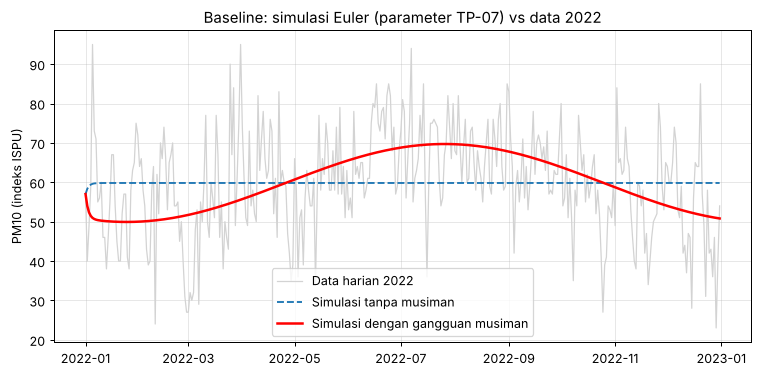

In [6]:
C0 = y[0]
t, C_tp = euler(k, E0, A_awal, t0_awal, C0, t_akhir=len(y) - 1)
_, C_tanpa_musim = euler(k, E0, 0.0, 0.0, C0, t_akhir=len(y) - 1)

m_tp = metrik(y, C_tp)
m_tanpa = metrik(y, C_tanpa_musim)
print("Tanpa gangguan musiman :", {a: round(b, 3) for a, b in m_tanpa.items()})
print("Parameter TP-07        :", {a: round(b, 3) for a, b in m_tp.items()})

plt.plot(pm10_2022.index, y, color="lightgray", lw=1, label="Data harian 2022")
plt.plot(pm10_2022.index, C_tanpa_musim, "--", label="Simulasi tanpa musiman")
plt.plot(pm10_2022.index, C_tp, color="red", lw=2, label="Simulasi dengan gangguan musiman")
plt.title("Baseline: simulasi Euler (parameter TP-07) vs data 2022")
plt.ylabel("PM10 (indeks ISPU)")
plt.legend()
plt.show()

**Interpretasi.** Tanpa gangguan musiman, simulasi hanya berupa garis yang menuju steady state $C^*=59,8$ sehingga $R^2\approx 0,001$ (setara memakai rata-rata saja). Dengan gangguan sinusoida, $R^2$ naik menjadi 0,161 dan RMSE turun dari 13,3 ke 12,2. Garis simulasi tampak **halus** sedangkan data harian **bergerigi** karena model tidak memuat cuaca harian (angin, hujan, kejadian emisi sesaat); model hanya menangkap kecenderungan musiman.

## 5. Kalibrasi dan Validasi
`k` dan `E0` dikunci dari regresi (nilainya punya arti fisik: waktu paruh sekitar 1,5 hari). Yang dikalibrasi hanya **amplitudo A** dan **fase t0** gangguan musiman dengan *least squares*. Karena model tidak memuat fluktuasi harian, validasi juga dilakukan terhadap rata-rata bergerak 30 hari dan rata-rata bulanan.

Hasil kalibrasi: A = 3.76 indeks/hari, t0 = 105.1
                      Harian (RMSE)  Harian (R2)  Rata-rata 30 hari (R2)  Rata-rata bulanan (R2)
Parameter awal TP-07         12.193        0.161                   0.679                   0.748
Setelah kalibrasi            12.080        0.176                   0.751                   0.852


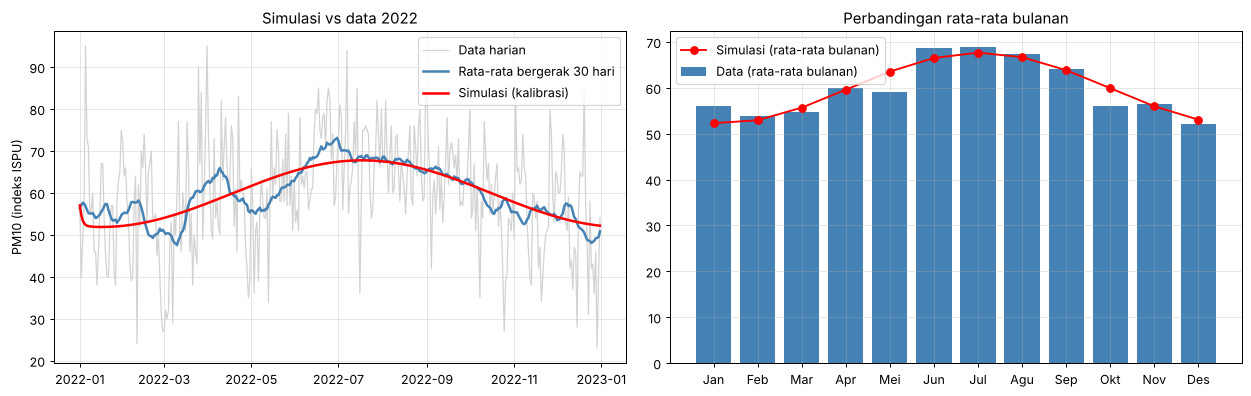

In [7]:
# Kalibrasi hanya A dan t0 (k dan E0 dikunci dari regresi)
A_cal, t0_cal = kalibrasi_musiman(y, k, E0, A_awal, t0_awal)
t, C_cal = euler(k, E0, A_cal, t0_cal, C0, t_akhir=len(y) - 1)

ma30 = pm10_2022.rolling(30, center=True, min_periods=15).mean().values
bulan_data = pm10_2022.groupby(pm10_2022.index.month).mean().values
def rata_bulanan(C):
    return pd.Series(C, index=pm10_2022.index).groupby(pm10_2022.index.month).mean().values

m_harian_tp, m_harian_cal = metrik(y, C_tp), metrik(y, C_cal)
m_ma_tp, m_ma_cal = metrik(ma30, C_tp), metrik(ma30, C_cal)
m_bln_tp, m_bln_cal = metrik(bulan_data, rata_bulanan(C_tp)), metrik(bulan_data, rata_bulanan(C_cal))

tabel = pd.DataFrame({
    "Harian (RMSE)": [m_harian_tp["RMSE"], m_harian_cal["RMSE"]],
    "Harian (R2)": [m_harian_tp["R2"], m_harian_cal["R2"]],
    "Rata-rata 30 hari (R2)": [m_ma_tp["R2"], m_ma_cal["R2"]],
    "Rata-rata bulanan (R2)": [m_bln_tp["R2"], m_bln_cal["R2"]],
}, index=["Parameter awal TP-07", "Setelah kalibrasi"]).round(3)

print(f"Hasil kalibrasi: A = {A_cal:.2f} indeks/hari, t0 = {t0_cal:.1f}")
print(tabel.to_string())

fig, ax = plt.subplots(1, 2, figsize=(14, 4.5))
ax[0].plot(pm10_2022.index, y, color="lightgray", lw=1, label="Data harian")
ax[0].plot(pm10_2022.index, ma30, color="steelblue", lw=2, label="Rata-rata bergerak 30 hari")
ax[0].plot(pm10_2022.index, C_cal, color="red", lw=2, label="Simulasi (kalibrasi)")
ax[0].set_title("Simulasi vs data 2022"); ax[0].set_ylabel("PM10 (indeks ISPU)"); ax[0].legend()
bln = ["Jan","Feb","Mar","Apr","Mei","Jun","Jul","Agu","Sep","Okt","Nov","Des"]
ax[1].bar(bln, bulan_data, color="steelblue", label="Data (rata-rata bulanan)")
ax[1].plot(bln, rata_bulanan(C_cal), "o-", color="red", label="Simulasi (rata-rata bulanan)")
ax[1].set_title("Perbandingan rata-rata bulanan"); ax[1].legend()
plt.tight_layout(); plt.show()

**Interpretasi.** Kalibrasi mengubah $A$ dari 4,68 menjadi 3,76 dan $t_0$ dari 113,7 menjadi 105,1. Terhadap data harian, $R^2$ hanya 0,176, tetapi terhadap rata-rata 30 hari naik menjadi 0,751 dan terhadap rata-rata bulanan menjadi 0,852. Jadi model **berhasil meniru pola musiman** (rendah di musim hujan, tinggi di musim kemarau) tetapi **tidak meniru fluktuasi harian**.

## 6. Pengaruh Step Size: Euler vs `solve_ivp`
Untuk melihat pengaruh langkah waktu, dibandingkan respon terhadap step pengurangan emisi 20% (hari ke-90) antara Euler $\Delta t=1$, Euler $\Delta t=0{,}1$, dan solver SciPy `solve_ivp` (adaptif).

Selisih maks Euler dt=1   vs solve_ivp (k sama): 1.323
Selisih maks Euler dt=0.1 vs solve_ivp (k sama): 0.106
k kontinu setara = 0.6408, selisih maks Euler dt=1 vs solve_ivp(k kontinu): 0.000010


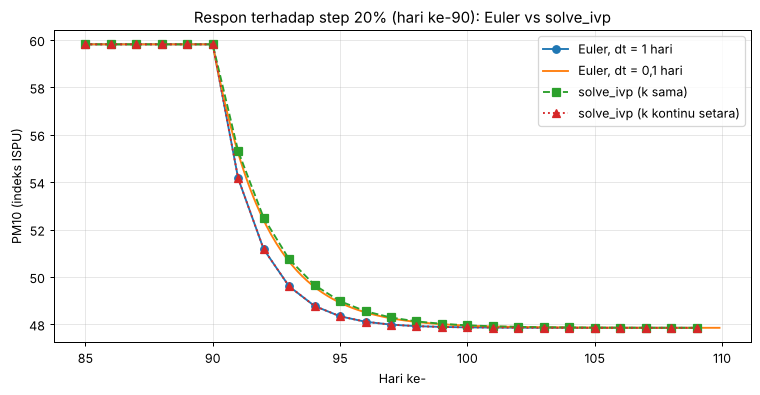

In [8]:
# Skenario uji: step 20% mulai hari ke-90, tanpa gangguan musiman, mulai dari steady state
u_step = lambda tt: kontrol_u(tt, "step", u_maks=0.2, t_mulai=90)
t1, C_dt1 = euler(k, E0, 0, 0, C_star, u_step, dt=1.0)
t01, C_dt01 = euler(k, E0, 0, 0, C_star, u_step, dt=0.1)
t_i, C_ivp = solusi_ivp(k, E0, 0, 0, C_star, u_step)

# k kontinu yang setara dengan Euler dt = 1 hari:  1 - k = exp(-k_kont)
k_kont = -np.log(1 - k)
E0_kont = k_kont * C_star
_, C_ivp_kont = solusi_ivp(k_kont, E0_kont, 0, 0, C_star, u_step)

selisih_dt1 = np.max(np.abs(C_dt1 - C_ivp))
selisih_dt01 = np.max(np.abs(C_dt01[::10] - C_ivp))
selisih_kont = np.max(np.abs(C_dt1 - C_ivp_kont))
print(f"Selisih maks Euler dt=1   vs solve_ivp (k sama): {selisih_dt1:.3f}")
print(f"Selisih maks Euler dt=0.1 vs solve_ivp (k sama): {selisih_dt01:.3f}")
print(f"k kontinu setara = {k_kont:.4f}, selisih maks Euler dt=1 vs solve_ivp(k kontinu): {selisih_kont:.6f}")

lo, hi = 85, 110
plt.plot(t1[lo:hi], C_dt1[lo:hi], "o-", label="Euler, dt = 1 hari")
plt.plot(t01[lo*10:hi*10], C_dt01[lo*10:hi*10], "-", label="Euler, dt = 0,1 hari")
plt.plot(t_i[lo:hi], C_ivp[lo:hi], "s--", label="solve_ivp (k sama)")
plt.plot(t_i[lo:hi], C_ivp_kont[lo:hi], "^:", label="solve_ivp (k kontinu setara)")
plt.title("Respon terhadap step 20% (hari ke-90): Euler vs solve_ivp")
plt.xlabel("Hari ke-"); plt.ylabel("PM10 (indeks ISPU)"); plt.legend()
plt.show()

**Interpretasi.** Dengan nilai $k$ yang sama, Euler $\Delta t=1$ hari berbeda dari `solve_ivp` hingga 1,32 indeks, sedangkan Euler $\Delta t=0{,}1$ hari hanya berbeda 0,11: makin kecil $h$, makin dekat ke solusi sebenarnya. Namun $k=0,473$ dari regresi sebenarnya adalah $k$ versi Euler 1 hari. Padanan kontinunya adalah $k_{kont}=-\ln(1-k)=0,641$/hari; dengan nilai itu `solve_ivp` berimpit dengan Euler $\Delta t=1$ (selisih maksimum hanya sekitar 0,00001).

## 7. Eksperimen What-If: Pengurangan Emisi
Tiga jenis sinyal kontrol $u(t)$ diuji terhadap baseline pada satu plot: **step** (pengurangan 20% langsung mulai hari ke-90), **ramp** (naik bertahap 0 ke 20% selama hari ke-90 sampai 180), dan **sinusoida** (naik-turun antara 0 dan 20% dengan periode 60 hari).

Rata-rata PM10 pada hari ke-180 s.d. 364:
  Baseline (u = 0)                         61.2   selisih   +0.0   ( +0.0%)
  Step 20% (mulai hari 90)                 49.3   selisih  -12.0   (-19.5%)
  Ramp 0 -> 20% (hari 90-180)              49.3   selisih  -12.0   (-19.5%)
  Sinusoida 0-20% (periode 60 hari)        55.1   selisih   -6.1   (-10.0%)


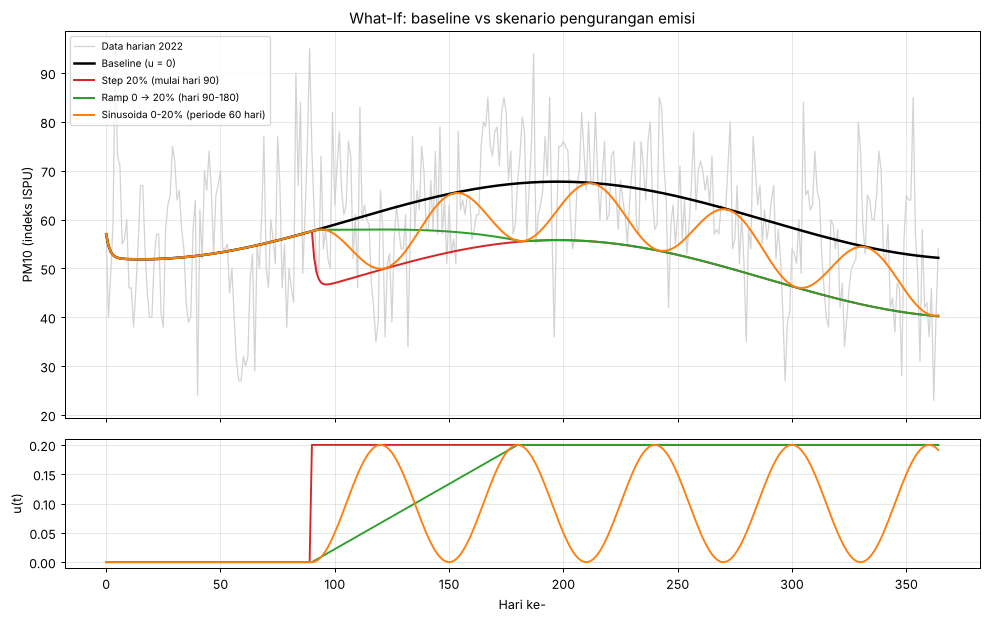

In [9]:
skenario = {
    "Baseline (u = 0)": None,
    "Step 20% (mulai hari 90)": lambda tt: kontrol_u(tt, "step", 0.2, 90),
    "Ramp 0 -> 20% (hari 90-180)": lambda tt: kontrol_u(tt, "ramp", 0.2, 90, 90),
    "Sinusoida 0-20% (periode 60 hari)": lambda tt: kontrol_u(tt, "sinusoida", 0.2, 90, periode=60),
}
hasil = {}
for nama, fn in skenario.items():
    _, Cx = euler(k, E0, A_cal, t0_cal, C0, fn, t_akhir=len(y) - 1)
    hasil[nama] = Cx

tt = np.arange(len(y))
fig, ax = plt.subplots(2, 1, figsize=(11, 7), sharex=True, gridspec_kw={"height_ratios": [3, 1]})
ax[0].plot(tt, y, color="lightgray", lw=1, label="Data harian 2022")
warna = ["black", "tab:red", "tab:green", "tab:orange"]
for (nama, Cx), w in zip(hasil.items(), warna):
    ax[0].plot(tt, Cx, color=w, lw=2 if "Baseline" in nama else 1.6, label=nama)
ax[0].set_ylabel("PM10 (indeks ISPU)"); ax[0].set_title("What-If: baseline vs skenario pengurangan emisi"); ax[0].legend(fontsize=8)
for (nama, fn), w in zip(list(skenario.items())[1:], warna[1:]):
    ax[1].plot(tt, fn(tt), color=w, label=nama)
ax[1].set_ylabel("u(t)"); ax[1].set_xlabel("Hari ke-")
plt.tight_layout(); plt.show()

dasar = hasil["Baseline (u = 0)"][180:].mean()
ringkas = {}
for nama, Cx in hasil.items():
    rata = Cx[180:].mean()
    ringkas[nama] = (rata, rata - dasar, (rata / dasar - 1) * 100)
print("Rata-rata PM10 pada hari ke-180 s.d. 364:")
for nama, (r_, d_, p_) in ringkas.items():
    print(f"  {nama:38s} {r_:6.1f}   selisih {d_:+6.1f}   ({p_:+5.1f}%)")

In [10]:
# Steady state untuk berbagai tingkat pengurangan emisi: C* = E0 (1 - u) / k
tabel_ss = pd.DataFrame({"u": [0, 0.1, 0.2, 0.3, 0.5]})
tabel_ss["C* (indeks)"] = (E0 * (1 - tabel_ss["u"]) / k).round(1)
tabel_ss["Perubahan"] = ((1 - tabel_ss["u"]) - 1).map(lambda v: f"{v*100:.0f}%")
print(tabel_ss.to_string(index=False))

# Berapa hari sampai 95% perubahan setelah step 20%?
_, C_s = euler(k, E0, 0, 0, C_star, u_step)
C_baru = E0 * 0.8 / k
frac = (C_s - C_star) / (C_baru - C_star)
hari_95 = int(np.argmax((frac >= 0.95) & (np.arange(len(frac)) >= 90)) - 90)
print(f"\nSetelah step 20%, 95% perubahan tercapai dalam {hari_95} hari (waktu paruh {t_paruh:.1f} hari).")

  u  C* (indeks) Perubahan
0.0         59.8        0%
0.1         53.8      -10%
0.2         47.9      -20%
0.3         41.9      -30%
0.5         29.9      -50%

Setelah step 20%, 95% perubahan tercapai dalam 5 hari (waktu paruh 1.5 hari).


**Interpretasi.**
- **Step 20%:** rata-rata PM10 pada hari ke-180 s.d. 364 turun dari 61,2 menjadi 49,3 (**-19,5%**). Sistem mencapai keadaan setimbang baru ($C^*=47{,}9$) dalam sekitar **5 hari**, karena waktu paruhnya pendek (1,5 hari).
- **Ramp:** hasil akhirnya sama dengan step (**-19,5%**) tetapi penurunannya bertahap, mengikuti naiknya $u$.
- **Sinusoida:** rata-rata $u$ hanya 0,1 sehingga penurunannya sekitar setengah (-10,0%), dan PM10 ikut berosilasi mengikuti sinyal karena responsnya cepat.
- Model ini **linear**: pengurangan emisi 20% menurunkan $C^*$ tepat 20% (59,8 menjadi 47,9). Umpan balik negatif membuat sistem selalu cepat menyesuaikan diri dengan emisi.

## 8. Kesimpulan dan Keterbatasan

**Kesimpulan**
1. Model ODE orde satu dengan umpan balik negatif cukup untuk meniru **pola musiman** PM10 Jakarta 2022, tetapi tidak meniru fluktuasi harian.
2. Parameter hasil regresi bermakna: pembersihan alami cepat (waktu paruh sekitar 1,5 hari) sehingga PM10 hampir mengikuti emisi dan musim.
3. Eksperimen What-If menunjukkan efek pengurangan emisi cepat dan sebanding: pengurangan 20% emisi menurunkan PM10 sekitar 20% dalam sekitar 5 hari.

**Keterbatasan**
- Nilai ISPU adalah **indeks** (bukan konsentrasi $\mu g/m^3$) dan melalui proses pelaporan.
- Kolom stasiun **berganti-ganti** antar hari sehingga deret waktu adalah gabungan beberapa stasiun (tambahan noise).
- Satu tahun data (2022), parameter konstan, tanpa variabel cuaca harian.
- Hasil What-If adalah **simulasi** perilaku sistem, bukan prediksi kebijakan operasional.